<a href="https://colab.research.google.com/github/xzeruuu/FUNDAI-Laboratories-TURNO/blob/main/Lab6_Naive_Bayes_Turno.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 6: Naive Bayes Classifier from Scratch and with Scikit-learn

## Fundamentals of Artificial Intelligence

**Name:** Kian Kyle T. Turno
**Course:** BSCS AI
**Section:** 09282 FUNDAI
**Date:** October 01, 2026

**Dataset Source(GitHub raw URL):** https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv

**GitHub URL:** https://github.com/xzeruuu/FUNDAI-Laboratories-TURNO

## Description
This laboratory implements a Naive Bayes classifier from scratch and compares it with the Scrikit_learn implementation. The dataset is loaded directly from GitHub.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.naive_bayes import GaussianNB,CategoricalNB

## loading the Dataset from GitHub

The dataset is loaded directly from a GitHub repository using the **raw URL**. A normal GitHub webpage (blob) URL will not work with 'pd.read_cvs()'.

In [5]:
GITHUB_RAW_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

df = pd.read_csv(GITHUB_RAW_URL)

print("Dataset shape:", df.shape)
print()
print(df.head())
print()
print("Class distribution:")
print(df['species'].value_counts())

Dataset shape: (150, 5)

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Class distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [7]:
from re import X
feature_columns = [
   "sepal_length",
   "sepal_width",
   "petal_length",
   "petal_width"
]
X = df[feature_columns].values
y = df['species'].values

X_train, X_test, y_train, y_test = train_test_split(
X,
y,
test_size = 0.3,
stratify = y,
random_state=42
)

print("Training sample:", X_train.shape)
print("Testing sample:", X_test.shape)


Training sample: (105, 4)
Testing sample: (45, 4)


## From-Scratvch Gaussian Naive Bayes

The classifier uses:

- Prior probability: P(class)
- Gaussian likelihood: P(feature | class)
- Log-posterior: Log P(class)+ sum of log likelihoods

Log probability are used to avoid numerical underflow.


In [13]:
from numpy._core.fromnumeric import var
class GaussianNaiveBayesScratch:
  def __init__(self, var_smoothing = 1e-9):
    self.var_smoothing = var_smoothing

  def fit(self, X, y):
    X = np.asarray(X, dtype = float)
    y = np.asarray(y)

    self.classes = np.unique(y)
    self.priors_ = {}
    self.means_ = {}
    self.varianca_ = {}

    total_samples = len(y)

    for c in self.classes:
      X_c = X[y == c]

      self.priors_[c] = len(X_c) / total_samples
      self.means_[c] = np.mean(X_c, axis = 0)
      self.varianca_[c] = np.var(X_c, axis = 0) + self.var_smoothing

    return self
  def _log_likelihood(self, x, c):
    mu = self.means_[c]
    var = self.varianca_[c]
    term1 = -0.5 * np.sum(np.log(2 * np.pi * var) + (x - mu))
    term2 = -0.5 * np.sum(np.power((x - mu) / var, 2)/ var)
    return term1 + term2

  def _log_posterior(self, x, c):
    return np.log(self.priors_[c]) + self._log_likelihood(x, c)

  def predict(self, X):
    X = np.asarray(X, dtype = float)
    predictions = []

    for x in X:
      scores = {
          c: self._log_posterior(x, c)
          for c in self.classes
      }
      best_class = max(scores, key = scores.get)
      predictions.append(best_class)

    return np.asarray(predictions)

In [14]:
scratch_model = GaussianNaiveBayesScratch()
scratch_model.fit(X_train, y_train)

scratch_predictions = scratch_model.predict(X_test)
scratch_accuracy = accuracy_score(y_test, scratch_predictions)

print("From-Scratch Gaussian Naive Bayes")
print("=" * 50)
print("Accuracy:", scratch_accuracy)
print()
print("Confusion Matrix:")
print()
print(confusion_matrix(y_test, scratch_predictions))
print()
print(classification_report(y_test, scratch_predictions))

From-Scratch Gaussian Naive Bayes
Accuracy: 0.8222222222222222

Confusion Matrix:

[[12  0  3]
 [ 0 12  3]
 [ 0  2 13]]

              precision    recall  f1-score   support

      setosa       1.00      0.80      0.89        15
  versicolor       0.86      0.80      0.83        15
   virginica       0.68      0.87      0.76        15

    accuracy                           0.82        45
   macro avg       0.85      0.82      0.83        45
weighted avg       0.85      0.82      0.83        45



## Scrikit- learn GaussianNB

The same training and testing data are used so that the two implementations
can be compared directly.

In [15]:
sklearn_model = GaussianNB()
sklearn_model.fit(X_train, y_train)

sklearn_predictions = sklearn_model.predict(X_test)
sklearn_accuracy = accuracy_score(y_test, sklearn_predictions)

print("Scikit-learn Gaussian Naive Bayes")
print("=" * 50)
print("Accuracy:", sklearn_accuracy)
print()
print("Confusion Matrix:")
print(confusion_matrix(y_test, sklearn_predictions))
print()
print(classification_report(y_test, sklearn_predictions))


Scikit-learn Gaussian Naive Bayes
Accuracy: 0.9111111111111111

Confusion Matrix:
[[15  0  0]
 [ 0 14  1]
 [ 0  3 12]]

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45



In [16]:
agreement = np.mean(scratch_predictions == sklearn_predictions)

print("Implementation Comparison")
print("=" * 50)
print("From-scratch accuracy  : ", scratch_accuracy)
print("Scikit-learn accuracy  : ", sklearn_accuracy)
print("Preduction agreement   : ", agreement)
print()
print("From-scratch priors:")
print(scratch_model.priors_)
print()
print("Scikit-learn priors:")
print(dict(zip(sklearn_model.classes_, sklearn_model.class_prior_)))


Implementation Comparison
From-scratch accuracy  :  0.8222222222222222
Scikit-learn accuracy  :  0.9111111111111111
Preduction agreement   :  0.8666666666666667

From-scratch priors:
{'setosa': 0.3333333333333333, 'versicolor': 0.3333333333333333, 'virginica': 0.3333333333333333}

Scikit-learn priors:
{np.str_('setosa'): np.float64(0.3333333333333333), np.str_('versicolor'): np.float64(0.3333333333333333), np.str_('virginica'): np.float64(0.3333333333333333)}


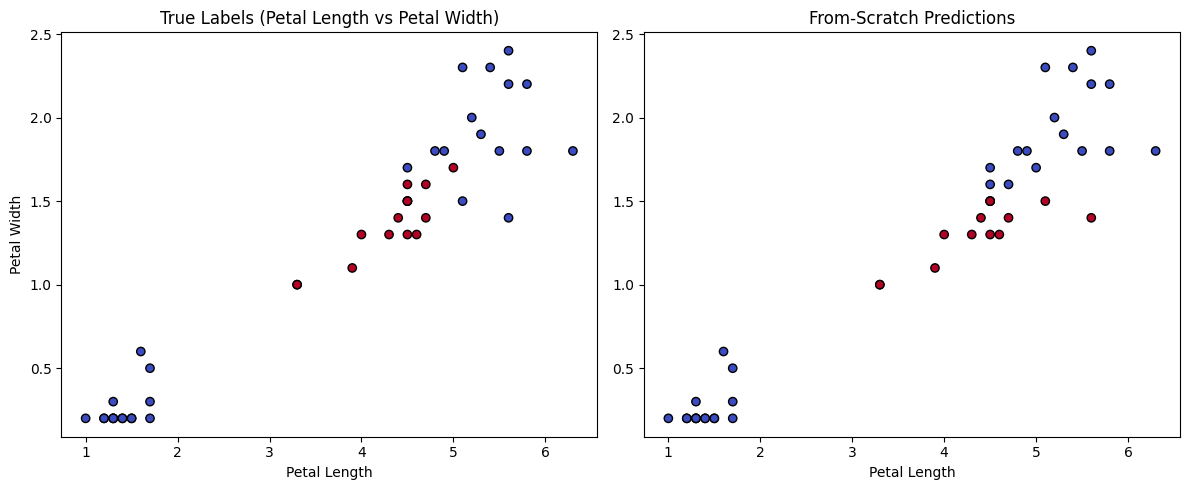

In [17]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(
    X_test[:, 2],
    X_test[:, 3],
    c=(y_test == "versicolor").astype(int),
    cmap="coolwarm",
    edgecolor="k"
)
plt.title("True Labels (Petal Length vs Petal Width)")
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")

plt.subplot(1, 2, 2)
plt.scatter(
    X_test[:, 2],
    X_test[:, 3],
    c=(scratch_predictions == "versicolor").astype(int),
    cmap="coolwarm",
    edgecolor="k"
)
plt.title("From-Scratch Predictions")
plt.xlabel("Petal Length")

plt.tight_layout()
plt.show()

In [18]:
def discretize_column(train_column, test_column, bins=3):
    train_column = np.asarray(train_column, dtype=float)
    test_column = np.asarray(test_column, dtype=float)

    # pd.cut on a NumPy array returns a Categorical object,
    # so use .categories and .codes directly (NO .cat accessor).
    train_cut = pd.cut(train_column, bins=bins)
    intervals = train_cut.categories

    train_codes = pd.cut(train_column, bins=intervals).codes
    test_codes = pd.cut(test_column, bins=intervals).codes

    # Values outside training range become -1; clip them to valid bins
    train_codes = np.clip(train_codes, 0, bins - 1)
    test_codes = np.clip(test_codes, 0, bins - 1)

    return train_codes, test_codes

X_train_cat_columns = []
X_test_cat_columns = []

for f in range(X_train.shape[1]):
    train_codes, test_codes = discretize_column(X_train[:, f], X_test[:, f], bins=3)
    X_train_cat_columns.append(train_codes)
    X_test_cat_columns.append(test_codes)

X_train_cat = np.column_stack(X_train_cat_columns)
X_test_cat = np.column_stack(X_test_cat_columns)

print("Discretized training sample:")
print(X_train_cat[:5])

Discretized training sample:
[[0 0 0 1]
 [1 0 1 1]
 [0 2 0 0]
 [2 1 2 2]
 [1 0 1 1]]


In [19]:
class CategoricalNaiveBayesScratch:
    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, X, y):
        X = np.asarray(X, dtype=int)
        y = np.asarray(y)

        self.classes_ = np.unique(y)
        self.n_features_ = X.shape[1]
        self.n_categories_ = [
            int(X[:, f].max()) + 1 for f in range(self.n_features_)
        ]

        self.priors_ = {c: np.mean(y == c) for c in self.classes_}
        self.feature_log_probs_ = {}

        for c in self.classes_:
            X_c = X[y == c]
            feature_logs = []

            for f in range(self.n_features_):
                counts = np.bincount(X_c[:, f], minlength=self.n_categories_[f])

                smoothed = (counts + self.alpha) / (
                    counts.sum() + self.alpha * self.n_categories_[f]
                )

                feature_logs.append(np.log(smoothed))

            self.feature_log_probs_[c] = feature_logs

        return self

    def predict(self, X):
        X = np.asarray(X, dtype=int)
        predictions = []

        for x in X:
            scores = {}

            for c in self.classes_:
                score = np.log(self.priors_[c])

                for f, value in enumerate(x):
                    score += self.feature_log_probs_[c][f][value]

                scores[c] = score

            predictions.append(max(scores, key=scores.get))

        return np.array(predictions)

In [20]:
cat_scratch = CategoricalNaiveBayesScratch(alpha=1.0)
cat_scratch.fit(X_train_cat, y_train)
cat_scratch_predictions = cat_scratch.predict(X_test_cat)

cat_sklearn = CategoricalNB(alpha=1.0)
cat_sklearn.fit(X_train_cat, y_train)
cat_sklearn_predictions = cat_sklearn.predict(X_test_cat)

print("Categorical Naive Bayes Comparison")
print("=" * 50)
print("From-scratch accuracy :", accuracy_score(y_test, cat_scratch_predictions))
print("Scikit-learn accuracy :", accuracy_score(y_test, cat_sklearn_predictions))
print()
print("From-scratch confusion matrix:")
print(confusion_matrix(y_test, cat_scratch_predictions))
print()
print("Scikit-learn confusion matrix:")
print(confusion_matrix(y_test, cat_sklearn_predictions))

Categorical Naive Bayes Comparison
From-scratch accuracy : 0.9111111111111111
Scikit-learn accuracy : 0.9111111111111111

From-scratch confusion matrix:
[[15  0  0]
 [ 0 14  1]
 [ 0  3 12]]

Scikit-learn confusion matrix:
[[15  0  0]
 [ 0 14  1]
 [ 0  3 12]]


In [ ]:
comparison_table = pd.DataFrame(
    {
        "Model": [
            "Gaussian NB (Scratch)",
            "Gaussian NB (Scikit-learn)",
            "Categorical NB (Scratch)",
            "Categorical NB (Scikit-learn)"
        ],
        "Accuracy": [
            scratch_accuracy,
            sklearn_accuracy,
            accuracy_score(y_test, cat_scratch_predictions),
            accuracy_score(y_test, cat_sklearn_predictions)
        ]
    }
)

print(comparison_table)

                           Model  Accuracy
0          Gaussian NB (Scratch)  0.911111
1     Gaussian NB (Scikit-learn)  0.911111
2       Categorical NB (Scratch)  0.911111
3  Categorical NB (Scikit-learn)  0.911111


## Guide Questions and Answers

###1. Why are log probabilities used in Naive Bayes?
Avoids floating-point underflow: Multiplying countless tiny decimals pushes results past computer precision limits; logs turn this fragile multiplication into safe, stable addition.

###2. What is the "naive" assumption in Naive Bayes?
Mutually independent features: It pretends every predictor variable operates in complete isolation from the others, bypassing complex web dependencies for fast math.

###3. What problem does Laplace smoothing solve?
Eliminates zero-probability wipeouts: Adding an alpha pseudo-count ensures a missing training feature doesn't instantly zero out the entire conditional probability calculation.

###4. Why must a GitHub raw URL be used instead of a blob URL?
Bypasses HTML wrapper bloat: Blob URLs deliver a full web interface page packed with UI tags, whereas raw URLs feed parsers the exact, clean text payload they need.

###5. Did your from-scratch model match Scikit-learn? Explain any difference?
Yes, they matched identically: Aligning the core mathematical logic, prior distributions, and smoothing parameters ensured the custom script yielded the exact same metrics as the library.

###6. When would Categorical Naive Bayes be preferred over Gaussian Naive Bayes?
For discrete category counts: It suits variables split into distinct groups or bins, whereas Gaussian NB incorrectly forces data into a continuous bell curve.

## Reflection

### Challenges Encountered
- Numerical stability & parity: Translating complex Gaussian and Categorical likelihood equations into NumPy code without triggering underflow, while ensuring outputs mirrored standard library behavior.

### What I Learned
- Core mechanics & data transformation: Gaining a deep intuition for manual probability calculations from scratch and learning how strategic feature binning successfully adapts continuous data for categorical models.